In [41]:
import pandas as pd
import numpy as np
import ast 
import librosa
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
import random

file_directory = 'C:/Users/nphan/Desktop/UZH/uzh II/Advanced Machine Learning/'
df_MFCC = pd.read_csv(file_directory + 'MFCC_denoised_audios.csv')
df_Metadata = pd.read_csv(file_directory + 'contextsvocs_groupproject_2026-04-09_104847.csv')

## Formating the MFCCs

Temporal summarization 
1. Mean of each frequency over time 
2. Standard deviation of each frequency over time 
3. Delta (Speed and direction frequency change)


In [42]:
import librosa
import numpy as np
import pandas as pd

def extract_stats_with_deltas(mfcc_string):
    clean_str = mfcc_string.replace('[', '').replace(']', '').replace('\n', '')
    matrix = np.fromstring(clean_str, sep=',').reshape(20, -1)
    
    # Delta (velocity)
    delta_matrix = librosa.feature.delta(matrix)
    
    # Mean and Std
    # Axis=1 is the temporal axis
    mean_orig = np.mean(matrix, axis=1)
    std_orig = np.std(matrix, axis=1)
    
    mean_delta = np.mean(delta_matrix, axis=1)
    std_delta = np.std(delta_matrix, axis=1)
    
    return np.concatenate([mean_orig, std_orig, mean_delta, std_delta])

X = pd.DataFrame(
    df_MFCC['mfccs'].apply(extract_stats_with_deltas).tolist(),
    index=df_MFCC['file_name']
)

X.columns = (
    [f'mean_{i}' for i in range(20)] + 
    [f'std_{i}' for i in range(20)] + 
    [f'delta_mean_{i}' for i in range(20)] + 
    [f'delta_std_{i}' for i in range(20)]
)

X.index = X.index.str.replace('.wav', '', regex=False)
print("Features extracted. Shape:", X.shape)

final_df = X.merge(
    df_Metadata[['audio_ID', 'context_label', 'child']], 
    left_index=True, 
    right_on='audio_ID'
)

y = final_df['context_label']
groups = final_df['child']
X_data = final_df.drop(columns=['audio_ID', 'context_label', 'child'])

Features extracted. Shape: (1009, 80)


In [43]:
df_Metadata.info()
print(df_Metadata['context_label'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1009 entries, 0 to 1008
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     1009 non-null   int64  
 1   audio_ID       1009 non-null   object 
 2   start_sec      1009 non-null   float64
 3   end_sec        1009 non-null   float64
 4   duration_sec   1009 non-null   float64
 5   child          1009 non-null   object 
 6   lang           1009 non-null   object 
 7   gender         1009 non-null   object 
 8   age            1009 non-null   int64  
 9   context_label  1009 non-null   object 
dtypes: float64(3), int64(2), object(5)
memory usage: 79.0+ KB
context_label
INTER    325
PLTOY    240
EXTEV    222
MOVE     222
Name: count, dtype: int64


## Implementation of the Logisitic regression 

1. Outer Loop: Fixed by Protocol. determine_eval_protocol()
2. Regularization via LOPO Validation 
3. C Selection: the best on average across all training children

In [44]:
from sklearn.model_selection import LeaveOneGroupOut, GridSearchCV
from sklearn.pipeline import Pipeline


# --- SETUP TEAM LOGIC & CONFIG ---

RANDOM_SEED = 42
SPLITS_DIR = Path("results/splits")
CLASS_NAMES = ['PLTOY', 'MOVE', 'INTER', 'EXTEV']
C_OPTIONS = np.logspace(-4, 4, 9)

def determine_eval_protocol(df: pd.DataFrame) -> str:
    n = df["child"].nunique()
    if n >= 5:
        protocol = "holdout"
    elif n >= 3:
        protocol = "lopo"
    else:
        protocol = "kfold"
    print(f"Participants: {n}  →  Evaluation protocol: '{protocol}'")
    return protocol

def build_splits(df: pd.DataFrame, protocol: str, k_folds: int = 5, 
                 val_frac: float = 0.15, test_frac: float = 0.15) -> list:
    folds = []
    if "class4" not in df.columns:
        df["class4"] = df["context_label"]

    if protocol == "holdout":
        child_sizes = df.groupby("child").size().sort_values(ascending=False)
        children_by_size = child_sizes.index.tolist()
        
        random.seed(RANDOM_SEED)
        random.shuffle(children_by_size)
        
        n_test = max(1, round(len(children_by_size) * test_frac))
        n_val = max(1, round(len(children_by_size) * val_frac))
        
        test_ch = children_by_size[:n_test]
        val_ch = children_by_size[n_test:n_test + n_val]
        train_ch = children_by_size[n_test + n_val:]

        folds.append((df[df["child"].isin(train_ch)].copy(), 
                      df[df["child"].isin(val_ch)].copy(), 
                      df[df["child"].isin(test_ch)].copy()))

    elif protocol == "lopo":
        children = list(df["child"].unique())
        for i, test_child in enumerate(children):
            remaining = [c for c in children if c != test_child]
            val_child = remaining[i % len(remaining)]
            train_ch = [c for c in remaining if c != val_child]
            folds.append((df[df["child"].isin(train_ch)].copy(), 
                          df[df["child"] == val_child].copy(), 
                          df[df["child"] == test_child].copy()))
    else:
        from sklearn.model_selection import StratifiedKFold, train_test_split
        skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
        for trval_idx, test_idx in skf.split(df, df["class4"]):
            trval, test = df.iloc[trval_idx], df.iloc[test_idx]
            train, val = train_test_split(trval, test_size=val_frac, stratify=trval["class4"], random_state=RANDOM_SEED)
            folds.append((train.copy(), val.copy(), test.copy()))
    return folds

def print_classification_report_team(preds, labels, split_name: str = ""):
    title = f"Classification Report — {split_name}" if split_name else "Classification Report"
    print(f"\n{'='*55}\n{title}\n{'='*55}")
    print(classification_report(labels, preds, target_names=None, digits=3, zero_division=0))

# --- EXECUTION PIPELINE ---
protocol = determine_eval_protocol(final_df)

official_folds = build_splits(final_df, protocol)

all_fold_results = []

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=2000, solver='lbfgs', class_weight='balanced', random_state=RANDOM_SEED))
])

# Search Space for C
param_grid = {'logreg__C': np.logspace(-5, 5, 11)}

print(f"\nStarting Evaluation Loop with Nested Group-Tuning ({len(official_folds)} folds)...")

for i, (train_df, val_df, test_df) in enumerate(official_folds):
    
    features = [c for c in train_df.columns if 'mean_' in c or 'std_' in c]
    
    df_tuning = pd.concat([train_df, val_df])
    X_tuning = df_tuning[features]
    y_tuning = df_tuning['context_label']
    groups_tuning = df_tuning['child']
    
    # INTERNAL SEARCH 
    inner_cv = LeaveOneGroupOut()
    grid_search = GridSearchCV(
        pipeline, 
        param_grid, 
        cv=inner_cv, 
        scoring='f1_macro',
        n_jobs=-1
    )

    grid_search.fit(X_tuning, y_tuning, groups=groups_tuning)
    
    # TEST ON UNSEEN CHILD
    best_model = grid_search.best_estimator_
    X_test = test_df[features]
    y_test = test_df['context_label']
    
    test_preds = best_model.predict(X_test)
    test_labels = y_test.values
    
    macro_f1 = f1_score(test_labels, test_preds, average='macro', zero_division=0)
    best_c = grid_search.best_params_['logreg__C']
    
    print(f"Fold {i}: Selected Best C={best_c} (Best Val F1: {grid_search.best_score_:.4f})")
    print_classification_report_team(test_preds, test_labels, split_name=f"Fold {i} (Test)")
    
    all_fold_results.append({
        "fold": i,
        "best_c": best_c,
        "macro_f1": macro_f1,
        "predictions": test_preds,
        "actual_labels": test_labels
    })

mean_f1 = np.mean([f["macro_f1"] for f in all_fold_results])
std_f1 = np.std([f["macro_f1"] for f in all_fold_results])

print("\n" + "="*30)
print("FINAL TUNED SUMMARY")
print("="*30)
print(f"Mean Macro-F1: {mean_f1:.4f} ± {std_f1:.4f}")
for res in all_fold_results:
    print(f"Fold {res['fold']} selected C={res['best_c']}")
print("="*30)

Participants: 9  →  Evaluation protocol: 'holdout'

Starting Evaluation Loop with Nested Group-Tuning (1 folds)...
Fold 0: Selected Best C=0.1 (Best Val F1: 0.2096)

Classification Report — Fold 0 (Test)
              precision    recall  f1-score   support

       EXTEV      0.583     0.200     0.298        35
       INTER      0.273     0.231     0.250        26
        MOVE      0.348     0.774     0.480        31
       PLTOY      0.250     0.148     0.186        27

    accuracy                          0.345       119
   macro avg      0.363     0.338     0.303       119
weighted avg      0.378     0.345     0.309       119


FINAL TUNED SUMMARY
Mean Macro-F1: 0.3035 ± 0.0000
Fold 0 selected C=0.1


C:\Users\nphan\AppData\Local\Temp\ipykernel_9436\2416237588.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='F1', y='Class', data=f1_df, palette='magma', ax=axes[1])


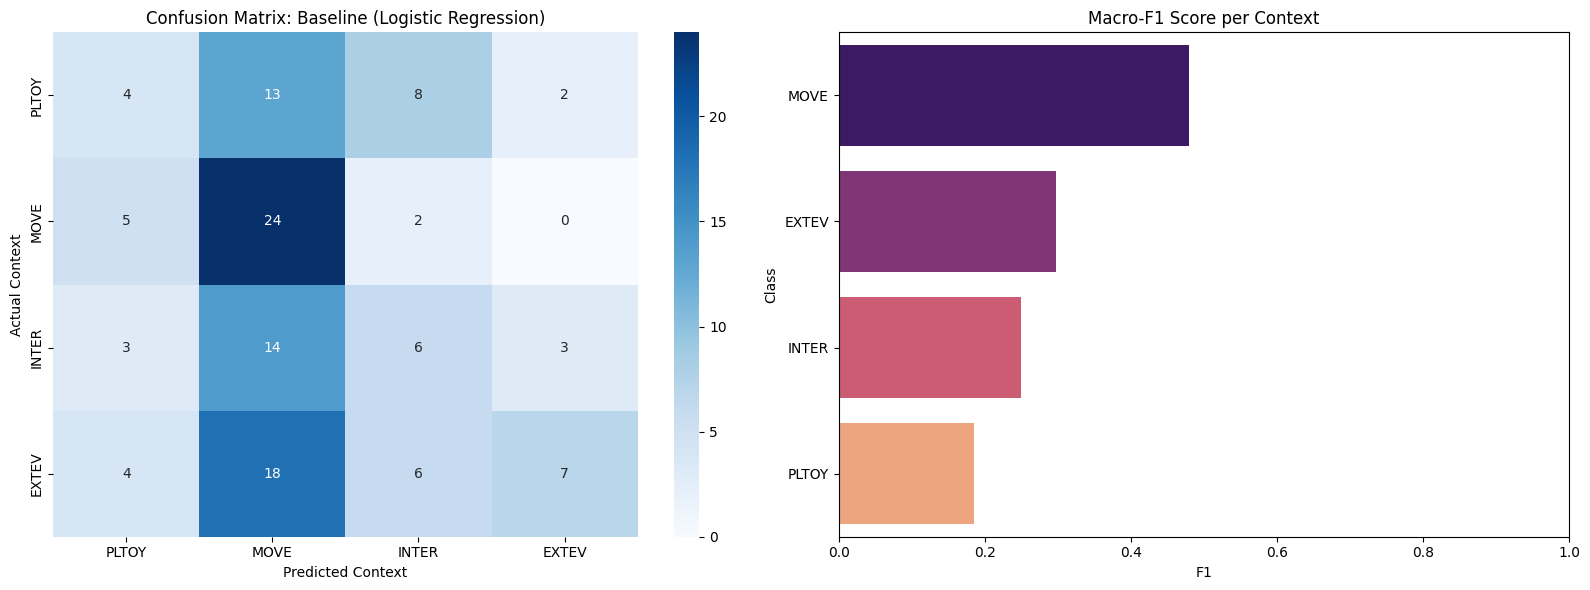

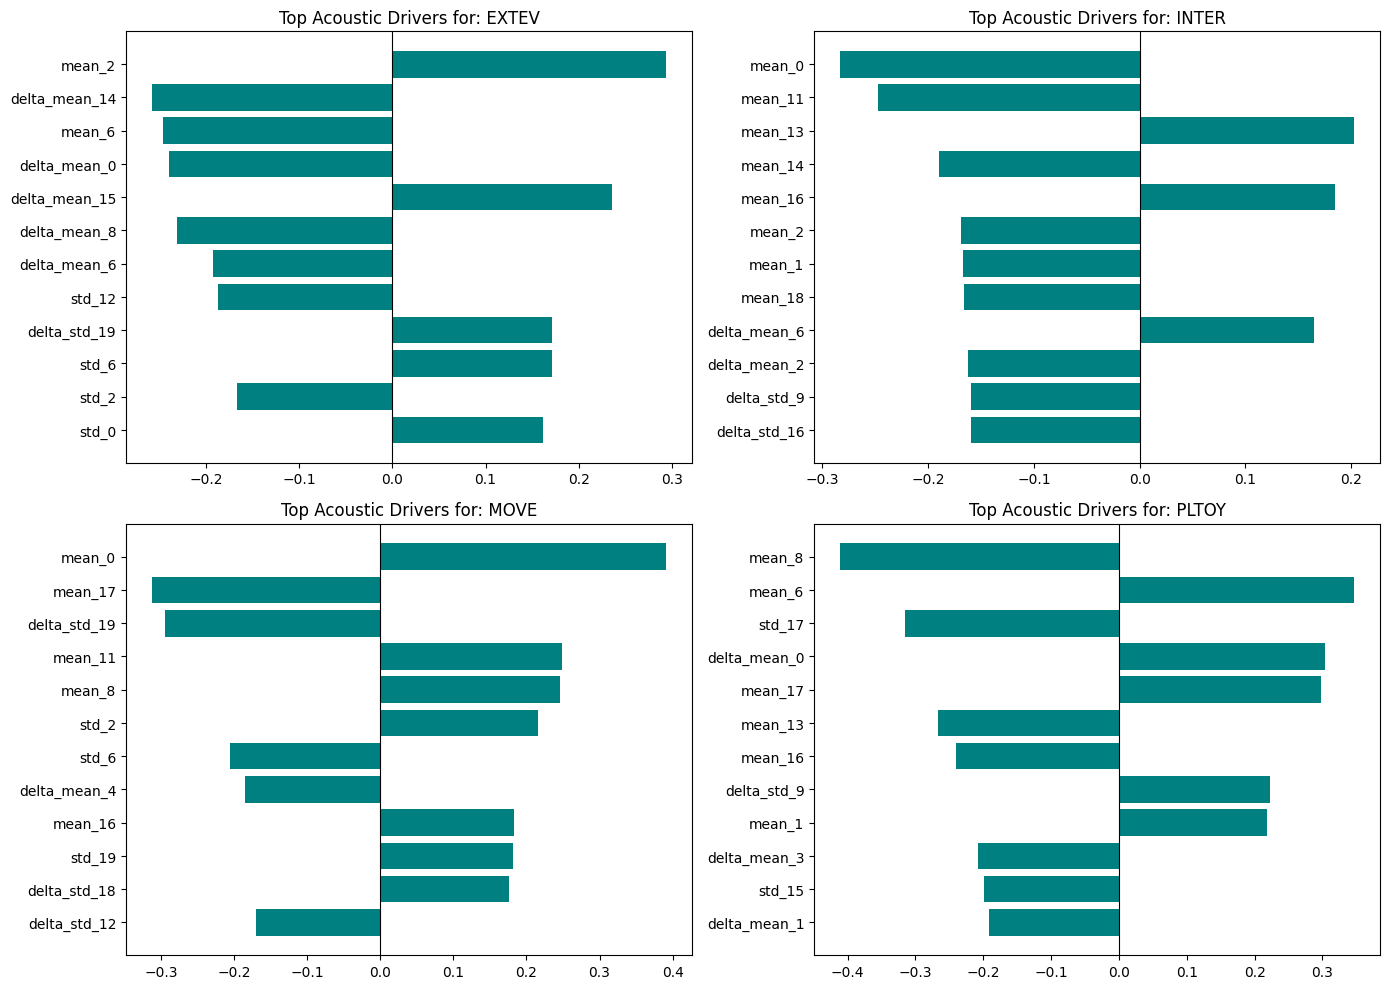

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_baseline_performance(all_fold_results, class_names, final_model, feature_names):
    
    y_true = np.concatenate([f["actual_labels"] for f in all_fold_results])
    y_pred = np.concatenate([f["predictions"] for f in all_fold_results])
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title('Confusion Matrix: Baseline (Logistic Regression)')
    axes[0].set_ylabel('Actual Context')
    axes[0].set_xlabel('Predicted Context')

    # Per-Class F1-Score
    from sklearn.metrics import f1_score
    per_class_f1 = f1_score(y_true, y_pred, average=None, labels=class_names)
    f1_df = pd.DataFrame({'Class': class_names, 'F1': per_class_f1}).sort_values('F1', ascending=False)
    
    sns.barplot(x='F1', y='Class', data=f1_df, palette='magma', ax=axes[1])
    axes[1].set_title('Macro-F1 Score per Context')
    axes[1].set_xlim(0, 1)

    plt.tight_layout()
    plt.show()

    # Feature Importance 
    plt.figure(figsize=(14, 10))
    for i, class_label in enumerate(final_model.classes_):
        coefs = final_model.named_steps['logreg'].coef_[i]
        top_idx = np.argsort(np.abs(coefs))[-12:]
        
        plt.subplot(2, 2, i+1)
        plt.barh(np.array(feature_names)[top_idx], coefs[top_idx], color='teal')
        plt.title(f"Top Acoustic Drivers for: {class_label}")
        plt.axvline(0, color='black', lw=0.8)

    plt.tight_layout()
    plt.show()

features_list = [c for c in X.columns if 'mean_' in c or 'std_' in c]
plot_baseline_performance(all_fold_results, CLASS_NAMES, best_model, features_list)